# Assignment VIII — Complete worked solutions
## No-cloning, teleportation, entanglement, and Deutsch's algorithm

**Name:** Ackaraphon Sahawiriya  **Student ID:** 6733291621



## 0. Environment and bit ordering

Tested with Python 3.12, Qiskit 2.6.0, and Qiskit Aer 0.17.2.
The commented cell is an installation command for Jupyter/Colab. Uncomment
only if packages are missing, then restart the kernel if requested.

In [1]:
# Uncomment once in Jupyter/Colab if needed:
# %pip install "qiskit==2.6.0" "qiskit-aer==0.17.2" "sympy==1.14.0" numpy matplotlib "pylatexenc==2.11"

In [2]:
import sys
from importlib.metadata import version
from itertools import product
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Math
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, DensityMatrix, Operator, partial_trace, state_fidelity
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

SEED, SHOTS, TOL = 2569, 1024, 1e-10
rng = np.random.default_rng(SEED)
sim = AerSimulator(method="density_matrix", max_parallel_threads=1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
sp.init_printing()
np.set_printoptions(precision=6, suppress=True)

print("Python:", sys.version.split()[0])
for package in ["qiskit", "qiskit-aer", "numpy", "sympy", "matplotlib", "pylatexenc"]:
    print(f"{package}: {version(package)}")
print(f"Ideal local density-matrix simulation; shots={SHOTS}, seed={SEED}")

I = sp.eye(2)
X = sp.Matrix([[0, 1], [1, 0]])
Y = sp.Matrix([[0, -sp.I], [sp.I, 0]])
Z = sp.diag(1, -1)
H = sp.Matrix([[1, 1], [1, -1]]) / sp.sqrt(2)
ket0, ket1 = sp.Matrix([1, 0]), sp.Matrix([0, 1])
plus, minus = (ket0 + ket1) / sp.sqrt(2), (ket0 - ket1) / sp.sqrt(2)
# In ordered basis |A B> = |00>,|01>,|10>,|11>:
CX_AB = sp.Matrix([[1,0,0,0], [0,1,0,0], [0,0,0,1], [0,0,1,0]])

def show_matrix(label, value):
    display(Math(label + " = " + sp.latex(sp.Matrix(value))))

def check(name, condition):
    assert bool(condition), name
    print("PASS:", name)

def as_np(value):
    return np.asarray(value, dtype=complex)

def clean_numeric_matrix(value):
    arr = np.asarray(value, dtype=complex)
    real = np.where(np.abs(arr.real)<TOL, 0, arr.real)
    imag = np.where(np.abs(arr.imag)<TOL, 0, arr.imag)
    return sp.Matrix(real+1j*imag).applyfunc(lambda x: sp.nsimplify(x,tolerance=TOL))

def draw(qc, title=None, fold=26):
    fig = qc.draw("mpl", fold=fold, idle_wires=True)
    if title:
        fig.suptitle(title, y=1.03)
    display(fig)
    plt.close(fig)

def run_aer(qc, shots=SHOTS, seed=SEED):
    compiled = transpile(qc, sim, optimization_level=0, seed_transpiler=seed)
    result = sim.run(compiled, shots=shots, seed_simulator=seed).result()
    if not result.success:
        raise RuntimeError(str(result.status))
    return result

def histogram(counts, title):
    fig = plot_histogram(counts, title=title, figsize=(8, 3.5), bar_labels=True)
    display(fig)
    plt.close(fig)

def table(headers, rows):
    display(Markdown("| " + " | ".join(headers) + " |\n| " +
                     " | ".join(["---"]*len(headers)) + " |\n" +
                     "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)))

Python: 3.12.14
qiskit: 2.6.0
qiskit-aer: 0.17.2
numpy: 2.3.5
sympy: 1.14.0
matplotlib: 3.10.8
pylatexenc: 2.11
Ideal local density-matrix simulation; shots=1024, seed=2569


### Read the strings before interpreting a histogram

Qiskit draws q[0] at the top by default but writes statevector labels as
$|q_{n-1}\cdots q_1q_0\rangle$. Bit 0 has weight $2^0$.
A single classical register is printed as c[n−1]...c[0].
Thus “top wire” and “most significant bit” are different concepts.

| Section | Quantum ket order | Classical output order |
|---|---|---|
| Q2 | $\vert q_1q_0\rangle=\vert A\,B\rangle$ | c1c0 = Alice outcome, Bob outcome |
| Q4–Q5 | $\vert q_2q_1q_0\rangle=\vert A\,BB\,B\rangle$ | Original Q5: c2c1c0 = $m_A,m_{BB},b$ |
| Q5 remapped | Same quantum order | c2c1c0 = $b,m_A,m_{BB}$ |
| Q7–Q10 | $\vert q_1q_0\rangle=\vert x\,y\rangle$ | Deutsch's single bit = measured $x$ |

This agrees with the upper Deutsch drawing in the handout: the lower wire
is the input $x=q_1$, while the upper wire is the work qubit $y=q_0$.
Changing the drawing order does not change the tensor-product convention.

## 1. No-cloning theorem

Assume one fixed physical operation $L$ clones every unknown pure state
into a blank target:
$$
L(|a\rangle|0\rangle)=|a\rangle|a\rangle,\qquad
L(|b\rangle|0\rangle)=|b\rangle|b\rangle.
$$

### Requested contradiction by expansion

It is enough to choose two orthonormal states $|a\rangle,|b\rangle$, since
a universal cloner would have to work for these and their superposition.
Then $|s\rangle=(|a\rangle+|b\rangle)/\sqrt2$ is normalized.
By linearity,
$$
L(|s\rangle|0\rangle)=\frac{|aa\rangle+|bb\rangle}{\sqrt2}.
$$
But the required cloned output is
$$
|s\rangle|s\rangle
=\frac{|aa\rangle+|ab\rangle+|ba\rangle+|bb\rangle}{2}.
$$
The four tensor-product basis states are orthonormal. The coefficient of
$|ab\rangle$ is $0$ on the first side and $1/2$ on the second side,
a contradiction. Equivalently, the unnormalized expression requested
in the question would have to satisfy both
$$
L((|a\rangle+|b\rangle)|0\rangle)=|aa\rangle+|bb\rangle
$$
and
$$
L((|a\rangle+|b\rangle)|0\rangle)
=\frac{|aa\rangle+|ab\rangle+|ba\rangle+|bb\rangle}{\sqrt2}.
$$
Therefore a linear universal cloning operation cannot exist.

**Normalization detail.** Normalized $a,b$ do not automatically make their
sum divided by $\sqrt2$ normalized:
$$
\left\|\frac{|a\rangle+|b\rangle}{\sqrt2}\right\|^2
=1+\operatorname{Re}\langle a|b\rangle.
$$
The general normalization factor is
$\sqrt{2+2\operatorname{Re}\langle a|b\rangle}$, unless the sum is zero.
Choosing orthogonal $a,b$ makes the handout's factor valid and suffices
to disprove universal cloning.

### Complementary inner-product proof

For a fixed unitary cloner, preservation of inner products gives, with
$s=\langle a|b\rangle$,
$$
s=\langle a0|b0\rangle=\langle aa|bb\rangle=s^2.
$$
Thus $s=0$ or $s=1$ for the exact vector equations above: orthogonal
states or the same vector. Allowing output global phases gives
$|s|=|s|^2$, so the physically allowed cases are orthogonal states or
the same ray. Distinct nonorthogonal states cannot both be perfectly cloned
by one fixed deterministic device.

An extra machine environment does not evade the conclusion. If its
normalized output states are $e_a,e_b$, inner-product preservation gives
$s=s^2\langle e_a|e_b\rangle$, which is impossible for $0<|s|<1$.

In [3]:
# A CNOT clones the chosen orthogonal computational basis but not |+>.
clone_inputs = {"0": ket0, "1": ket1, "+": plus}
rows = []
for name, v in clone_inputs.items():
    actual = sp.simplify(CX_AB * sp.kronecker_product(v, ket0))
    desired = sp.kronecker_product(v, v)
    fidelity = sp.simplify((desired.conjugate().T * actual)[0] *
                          (actual.conjugate().T * desired)[0])
    rows.append([f"state {name}", str(list(actual)), str(fidelity)])
table(["Input", "Actual CNOT output in A B order", "Fidelity with desired two-copy state"], rows)
actual_plus = CX_AB * sp.kronecker_product(plus, ket0)
show_matrix(r"L(|+\rangle|0\rangle)", actual_plus)
show_matrix(r"|+\rangle|+\rangle", sp.kronecker_product(plus, plus))
check("CNOT output differs from two independent copies of |+>",
      actual_plus != sp.kronecker_product(plus, plus))
rho_one = partial_trace(Statevector(as_np(actual_plus).ravel()), [1])
show_matrix(r"\rho_{\mathrm{one\ output}}", clean_numeric_matrix(rho_one.data))

PASS: CNOT output differs from two independent copies of |+>


| Input | Actual CNOT output in A B order | Fidelity with desired two-copy state |
| --- | --- | --- |
| state 0 | [1, 0, 0, 0] | 1 |
| state 1 | [0, 0, 0, 1] | 1 |
| state + | [sqrt(2)/2, 0, 0, sqrt(2)/2] | 1/2 |

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 2. Teleportation of a superposition state

### 2(a). Why is the input $|+\rangle$?

In Figure 1, Alice is $q_1$, Bob is $q_0$, and both start in $|0\rangle$.
The **first** Hadamard on Alice is state preparation:
$$
H|0\rangle_A=|+\rangle_A.
$$
The state entering Step 1's CNOT is $|+\rangle_A|0\rangle_B$.
The caption's $|\Psi\rangle=|0\rangle$ describes the state **before** this
preparation gate.

The figure is a **two-qubit state-transfer / one-bit teleportation circuit**:
it uses a direct $A\rightarrow B$ CNOT. It is not the complete three-qubit,
pre-shared-Bell-pair remote protocol of Q5.

### 2(b). The 4×4 matrix before Alice's first measurement

Use the ordered basis $(|00\rangle,|01\rangle,|10\rangle,|11\rangle)$
for $|A B\rangle=|q_1q_0\rangle$. The circuit operations are $H_A$,
$\mathrm{CX}_{A\to B}$, $H_A$; hence
$$
U=(H\otimes I)\,\mathrm{CX}_{A\to B}\,(H\otimes I).
$$
The rightmost Hadamard is the preparation gate.
$$
H\otimes I=\frac1{\sqrt2}
\begin{pmatrix}
1&0&1&0\\0&1&0&1\\1&0&-1&0\\0&1&0&-1
\end{pmatrix},\qquad
\mathrm{CX}_{A\to B}=
\begin{pmatrix}
1&0&0&0\\0&1&0&0\\0&0&0&1\\0&0&1&0
\end{pmatrix}.
$$
Multiplying,
$$
\boxed{U=\frac12\begin{pmatrix}
1&1&1&-1\\1&1&-1&1\\1&-1&1&1\\-1&1&1&1
\end{pmatrix}.}
$$
This is the unitary prefix **up to but excluding measurement**.
Measurement cannot be represented by one 4×4 unitary matrix.

PASS: U is unitary
PASS: Qiskit Operator equals the derived 4x4 matrix


<IPython.core.display.Math object>

<IPython.core.display.Math object>

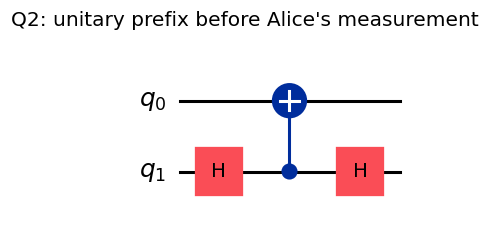

In [4]:
HI = sp.kronecker_product(H, I)
U2 = sp.simplify(HI * CX_AB * HI)
show_matrix(r"U", U2)
show_matrix(r"U|00\rangle", sp.simplify(U2 * sp.Matrix([1,0,0,0])))
check("U is unitary", sp.simplify(U2.conjugate().T * U2) == sp.eye(4))
prefix2 = QuantumCircuit(2, name="Q2_prefix")
prefix2.h(1)
prefix2.cx(1, 0)
prefix2.h(1)
draw(prefix2, "Q2: unitary prefix before Alice's measurement")
check("Qiskit Operator equals the derived 4x4 matrix",
      np.allclose(Operator(prefix2).data, as_np(U2), atol=TOL, rtol=0))

### 2(c). Branches, simulation, and what counts as success

For a general input $|\psi\rangle_A=\alpha|0\rangle+\beta|1\rangle$
at the entrance to the transfer protocol,
$$
|\psi\rangle_A|0\rangle_B
\xrightarrow{\mathrm{CX}}\alpha|00\rangle+\beta|11\rangle
\xrightarrow{H_A}
\frac{|0\rangle_A|\psi\rangle_B+
|1\rangle_A Z|\psi\rangle_B}{\sqrt2}.
$$
Alice obtains $m=0$ or $1$, each with probability $1/2$.
Bob applies $Z^m$, obtaining $|\psi\rangle$ in either branch.
For this figure,
$$
U|00\rangle=\frac{|00\rangle+|01\rangle+|10\rangle-|11\rangle}{2}
=\frac{|0\rangle|+\rangle+|1\rangle|-\rangle}{\sqrt2}.
$$

| Alice's result $m$ | Bob before correction | Correction | Bob afterward |
|---|---|---|---|
| 0 | $\vert +\rangle$ | $I$ | $\vert +\rangle$ |
| 1 | $\vert -\rangle$ | $Z$ | $\vert +\rangle$ |

Alice's outcome is stored in c[1]. At this point c[0]=0, so the whole
register values are 0 and 2. The figure's condition “== 2” means Alice measured 1.
The final Bob Z-basis measurement is stored in c[0]. All four strings
00, 01, 10, 11 have probability $1/4$.

**A flat Z histogram alone does not prove teleportation of $|+\rangle$.**
The mixed state $I/2$, and the uncorrected protocol, give the same Bob
Z probabilities. We therefore inspect Bob's density matrix and measure him
in the X basis. With correction, $\rho_B=|+\rangle\langle+|$ and
$P(X=+1)=1$; without correction the average state is $I/2$, so
$P(X=+1)=1/2$.

PASS: Bob's corrected state has fidelity 1 with |+>
PASS: All four final strings occur
PASS: Corrected Bob is always + in X basis


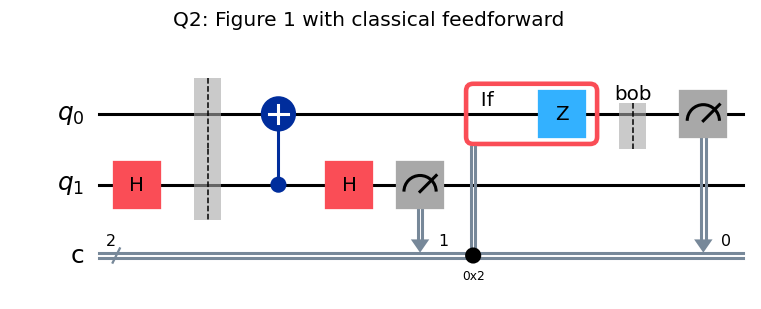

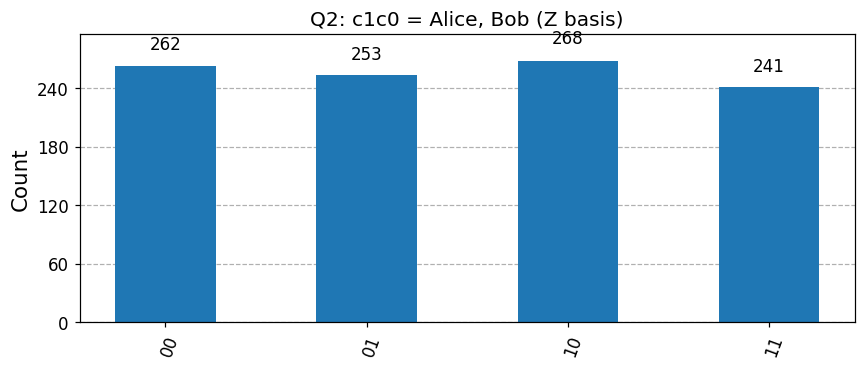

<IPython.core.display.Math object>

| Circuit | P(Bob X=+1), observed | Exact P | Bob purity before readout |
| --- | --- | --- | --- |
| With Z correction | 1.0000 | 1 | 1.0000 |
| Without correction | 0.5010 | 1/2 | 0.5000 |

In [5]:
def simplified_teleport(correct=True, basis="Z"):
    qc = QuantumCircuit(2, 2, name=f"Q2_{basis}")
    qc.h(1)                   # Prepare Alice's |+>.
    qc.barrier()
    qc.cx(1, 0)
    qc.h(1)
    qc.measure(1, 1)
    if correct:
        with qc.if_test((qc.cregs[0], 2)):
            qc.z(0)
    qc.save_density_matrix([0], label="bob")  # Before destructive final readout.
    if basis == "X":
        qc.h(0)               # Z measurement after H measures X.
    qc.measure(0, 0)
    return qc

q2_z = simplified_teleport()
draw(q2_z, "Q2: Figure 1 with classical feedforward")
r2_z = run_aer(q2_z)
histogram(r2_z.get_counts(), "Q2: c1c0 = Alice, Bob (Z basis)")
rho2 = DensityMatrix(r2_z.data()["bob"])
show_matrix(r"\rho_B", clean_numeric_matrix(rho2.data))
F2 = state_fidelity(rho2, Statevector(as_np(plus).ravel()))
check("Bob's corrected state has fidelity 1 with |+>", abs(F2-1) < TOL)
check("All four final strings occur", set(r2_z.get_counts()) == {"00","01","10","11"})

q2_x = run_aer(simplified_teleport(True, "X"))
q2_no = run_aer(simplified_teleport(False, "X"))
def bob_zero_fraction(counts, classical_index=0):
    return sum(n for s,n in counts.items() if s[-1-classical_index] == "0") / sum(counts.values())
table(["Circuit", "P(Bob X=+1), observed", "Exact P", "Bob purity before readout"],
      [["With Z correction", f"{bob_zero_fraction(q2_x.get_counts()):.4f}", "1",
        f"{np.trace(rho2.data @ rho2.data).real:.4f}"],
       ["Without correction", f"{bob_zero_fraction(q2_no.get_counts()):.4f}", "1/2",
        f"{np.trace(np.asarray(q2_no.data()['bob']) @ np.asarray(q2_no.data()['bob'])).real:.4f}"]])
check("Corrected Bob is always + in X basis", bob_zero_fraction(q2_x.get_counts()) == 1)

### 2(d). Why do the two Hadamards not cancel?

The identity $H^2=I$ applies to adjacent Hadamards, or if intervening
operations commute appropriately. Here the CNOT lies between them:
$$
(H\otimes I)\,\mathrm{CX}\,(H\otimes I)\ne I_4.
$$
$H_A$ and a CNOT **controlled by Alice** do not commute. The CNOT first
correlates Alice with Bob; the second H acts on part of that joint state,
rather than undoing the preparation on an isolated qubit.
The matrix in 2(b) has four nonzero entries in its first column, whereas
the identity's first column has only one.

Consequently the MSB c[1], Alice's measurement result, is random.
It is not Bob's output qubit. Its occurrence as both 0 and 1 is expected
and does not indicate teleportation failure.

In [6]:
commutator = sp.simplify(HI * CX_AB - CX_AB * HI)
check("H_A and CX_A->B do not commute", commutator != sp.zeros(4))
check("The prefix is not the identity", U2 != sp.eye(4))
print("Exact Alice marginal: P(c1=0)=P(c1=1)=1/2.")

PASS: H_A and CX_A->B do not commute
PASS: The prefix is not the identity
Exact Alice marginal: P(c1=0)=P(c1=1)=1/2.


## 3. No-cloning, change of basis, and uncertainty

Every pure qubit state belongs to some orthonormal basis
$\{|\psi\rangle,|\psi_\perp\rangle\}$. The crucial question is whether
that basis is **known in advance**.

**Known fixed basis.** Let $V|0\rangle=|\psi\rangle$ and
$V|1\rangle=|\psi_\perp\rangle$. A basis-dependent cloner is
$$
U_{\mathcal B}=(V\otimes V)\,\mathrm{CX}\,(V^\dagger\otimes I).
$$
For $j\in\{0,1\}$,
$$
U_{\mathcal B}(V|j\rangle\otimes|0\rangle)
=(V\otimes V)|jj\rangle=V|j\rangle\otimes V|j\rangle.
$$
It clones either member of that chosen orthogonal set. For the X basis take
$V=H$. A different basis generally requires a different device.

**Unknown arbitrary input.** The existence of some suitable basis does not
tell us which $V$ to implement. One copy of an unknown state does not
provide its full classical description. A fixed device cloning inputs from
every basis would be a universal cloner, excluded by Q1. Superpositions
of the two states of a clonable basis become entangled under its cloner,
rather than being copied into independent copies.

**Relation to uncertainty.** For two observables,
$$
\Delta A\,\Delta B\ge \tfrac12|\langle[A,B]\rangle|.
$$
For Pauli X and Z, $\Delta X\,\Delta Z\ge|\langle Y\rangle|$.
This bound is state dependent and can be zero; this single product inequality
is not by itself a general proof of no-cloning. On $|0\rangle$,
$\Delta Z=0,\Delta X=1$; on $|+i\rangle$, both uncertainties are 1.

Both uncertainty and no-cloning reflect the structure of quantum states and
incompatible measurements. A hypothetical universal cloner would make
arbitrarily many perfect copies of one unknown specimen, allowing estimates
of incompatible observables on different copies and arbitrarily accurate
identification of that one specimen's state. More directly, it would permit
arbitrarily reliable discrimination of initially nonorthogonal states,
contradicting quantum mechanics.

Measuring X and Z on different, legitimately prepared copies is allowed
and does not violate uncertainty. Uncertainty describes each state's intrinsic
measurement distributions; it is not merely ignorance of hidden simultaneously
sharp X and Z values.

In [7]:
U_xbasis = sp.simplify(sp.kronecker_product(H,H) * CX_AB * sp.kronecker_product(H,I))
for name, v in [("+", plus), ("-", minus)]:
    actual = sp.simplify(U_xbasis * sp.kronecker_product(v,ket0))
    desired = sp.kronecker_product(v,v)
    check(f"Known X-basis cloner copies |{name}>", actual == desired)

def pauli_variance(v, op):
    mean = (v.conjugate().T * op * v)[0]
    return sp.simplify((v.conjugate().T * op**2 * v)[0] - mean**2)
states_uncertainty = [("state 0", ket0), ("state +", plus),
                      ("state +i", sp.Matrix([1,sp.I])/sp.sqrt(2))]
table(["State", "Var(X)", "Var(Z)", "abs expectation Y"],
      [[name, pauli_variance(v,X), pauli_variance(v,Z),
        sp.simplify(abs((v.conjugate().T*Y*v)[0]))] for name,v in states_uncertainty])

PASS: Known X-basis cloner copies |+>
PASS: Known X-basis cloner copies |->


| State | Var(X) | Var(Z) | abs expectation Y |
| --- | --- | --- | --- |
| state 0 | 1 | 0 | 0 |
| state + | 0 | 1 | 0 |
| state +i | 1 | 1 | 1 |

## 4. Entanglement — derivation using matrices

The printed equation is
$$
\frac{\alpha|000\rangle+\beta|110\rangle+\alpha|011\rangle+\beta|101\rangle}{\sqrt2}
=\frac{\alpha|000\rangle+\beta|101\rangle+\alpha|011\rangle+\beta|110\rangle}{\sqrt2}.
$$
As written, this equality simply reorders vector addition. No gate is needed
to exchange the *position of terms in a written sum*. It does not mean
two quantum subsystems have physically been swapped.

To derive this state using matrices in the teleportation context, let
$$
|\psi\rangle_A=\alpha|0\rangle+\beta|1\rangle,\quad
|\Phi^+\rangle_{BB,B}=\frac{|00\rangle+|11\rangle}{\sqrt2},\quad
|\alpha|^2+|\beta|^2=1.
$$
In Qiskit order $|q_2q_1q_0\rangle=|A\,BB\,B\rangle$, the pre-CNOT state is
$$
v_{\rm in}=|\psi\rangle\otimes|\Phi^+\rangle
=\frac1{\sqrt2}
\begin{pmatrix}\alpha\\0\\0\\\alpha\\\beta\\0\\0\\\beta\end{pmatrix}.
$$
Alice controls $q_2$, targeting ancillary qubit $q_1$:
$$
M=\mathrm{CX}_{A\to BB}\otimes I_B=
\begin{pmatrix}
1&0&0&0&0&0&0&0\\
0&1&0&0&0&0&0&0\\
0&0&1&0&0&0&0&0\\
0&0&0&1&0&0&0&0\\
0&0&0&0&0&0&1&0\\
0&0&0&0&0&0&0&1\\
0&0&0&0&1&0&0&0\\
0&0&0&0&0&1&0&0
\end{pmatrix}.
$$
It maps $000\to000,\ 011\to011,\ 100\to110,\ 111\to101$. Therefore
$$
Mv_{\rm in}=\frac1{\sqrt2}
\begin{pmatrix}\alpha\\0\\0\\\alpha\\0\\\beta\\\beta\\0\end{pmatrix}.
$$
Reading this vector gives either side of the printed equation.
Grouping by the ancillary bit is useful for Q5:
$$
|\Omega\rangle=\frac1{\sqrt2}\left[
|0\rangle_{BB}\big(\alpha|0_A0_B\rangle+\beta|1_A1_B\rangle\big)
+|1\rangle_{BB}\big(\alpha|0_A1_B\rangle+\beta|1_A0_B\rangle\big)
\right].
$$
The last line groups the middle subsystem explicitly; it does not redefine
the stored $|A\,BB\,B\rangle$ matrix ordering.

In [8]:
alpha, beta = sp.symbols("alpha beta", complex=True)
bell = sp.Matrix([1,0,0,1]) / sp.sqrt(2)
v_in4 = sp.kronecker_product(sp.Matrix([alpha,beta]), bell)
M4 = sp.kronecker_product(CX_AB,I)
v_out4 = sp.simplify(M4*v_in4)
show_matrix(r"M", M4)
show_matrix(r"Mv_{\rm in}", v_out4)

basis8 = [sp.eye(8)[:,i] for i in range(8)]
lhs4 = (alpha*basis8[0]+beta*basis8[6]+alpha*basis8[3]+beta*basis8[5])/sp.sqrt(2)
rhs4 = (alpha*basis8[0]+beta*basis8[5]+alpha*basis8[3]+beta*basis8[6])/sp.sqrt(2)
check("Both written sums equal the derived column vector",
      sp.simplify(lhs4-v_out4)==sp.zeros(8,1) and sp.simplify(rhs4-v_out4)==sp.zeros(8,1))

q4_cx = QuantumCircuit(3)
q4_cx.cx(2,1)
check("The 8x8 matrix agrees with Qiskit's qubit order",
      np.allclose(Operator(q4_cx).data,as_np(M4),atol=TOL,rtol=0))
v_complex = np.array([np.sqrt(0.3), np.exp(0.7j)*np.sqrt(0.7)])
q4_state = QuantumCircuit(3)
q4_state.initialize(v_complex,[2])
q4_state.h(1)
q4_state.cx(1,0)
q4_state.cx(2,1)
expected4 = as_np(v_out4.subs({alpha:v_complex[0],beta:v_complex[1]})).ravel()
check("Complex-amplitude statevector agrees with the symbolic result",
      np.allclose(Statevector.from_instruction(q4_state).data,expected4,atol=TOL,rtol=0))

PASS: Both written sums equal the derived column vector
PASS: The 8x8 matrix agrees with Qiskit's qubit order
PASS: Complex-amplitude statevector agrees with the symbolic result


<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 5. Classical register and conditional gates

### 5(a). Reproduce Figures 2 and 3

The figure uses $q_0=B$, $q_1=BB$, $q_2=A$:

1. Prepare Alice's input $\alpha|0\rangle+\beta|1\rangle$.
2. Step 1a: $H_{q_1}$, $\mathrm{CX}_{q_1\to q_0}$ prepare the shared Bell
   pair, then $\mathrm{CX}_{q_2\to q_1}$ produces Q4's state.
3. Step 1b: measure $q_1$ into c[1]; if the register equals 2, apply
   $\mathrm{CX}_{q_1\to q_0}$. Since the measured control is then $|1\rangle$,
   this acts exactly as $X$ on Bob. A bit-conditioned X on Bob is equivalent.
4. Step 2: apply $H$ to $q_2$, then measure $q_2$ into c[2].
5. Step 3: apply $Z$ to Bob when the register is 4 or 6, meaning c[2]=1.
6. Finally measure Bob $q_0$ into c[0].

**Branch derivation in Figure 2's staged order.** Let $m_{BB}$ be Step 1b's
result. Before Bob's X correction the normalized Alice–Bob state is
$$
\alpha|0\rangle_A|m_{BB}\rangle_B+
\beta|1\rangle_A|1\oplus m_{BB}\rangle_B.
$$
Applying $X_B^{m_{BB}}$ gives $\alpha|00\rangle+\beta|11\rangle$.
After $H_A$ and Alice's outcome $m_A$, Bob has
$\alpha|0\rangle+(-1)^{m_A}\beta|1\rangle=Z^{m_A}|\psi\rangle$.
Then $Z_B^{m_A}$ recovers $|\psi\rangle$. Each pair
$(m_A,m_{BB})$ has probability $1/4$, independently of the input.

| $m_A$ | $m_{BB}$ | Bob before both corrections in the deferred version | Correction applied X then Z |
|---|---|---|---|
| 0 | 0 | $\vert \psi\rangle$ | $I$ |
| 0 | 1 | $X\vert \psi\rangle$ | $X$ |
| 1 | 0 | $Z\vert \psi\rangle$ | $Z$ |
| 1 | 1 | $XZ\vert \psi\rangle$ | $ZX$ |

The total correction operator is $Z^{m_A}X^{m_{BB}}$, since rightmost
operators act first. In the figure X is applied before Alice's second
measurement, which yields the same corrected output.

For genuinely separated parties, Bob implements this as his **local X gate
controlled by the received classical bit**. The literal measured-control CX
in the figure is not an additional required nonlocal quantum operation.

For $|0\rangle$, Bob's bit is always 0: 000,010,100,110 each have probability
$1/4$. For $|1\rangle$, Bob's bit is always 1: 001,011,101,111 each have
probability $1/4$. Bar heights need not match the handout exactly because
individual shots are random.

PASS: |0> output support matches Figure 3
PASS: |1> output support matches Figure 3
PASS: |0> input: Bob fidelity is 1
PASS: |1> input: Bob fidelity is 1


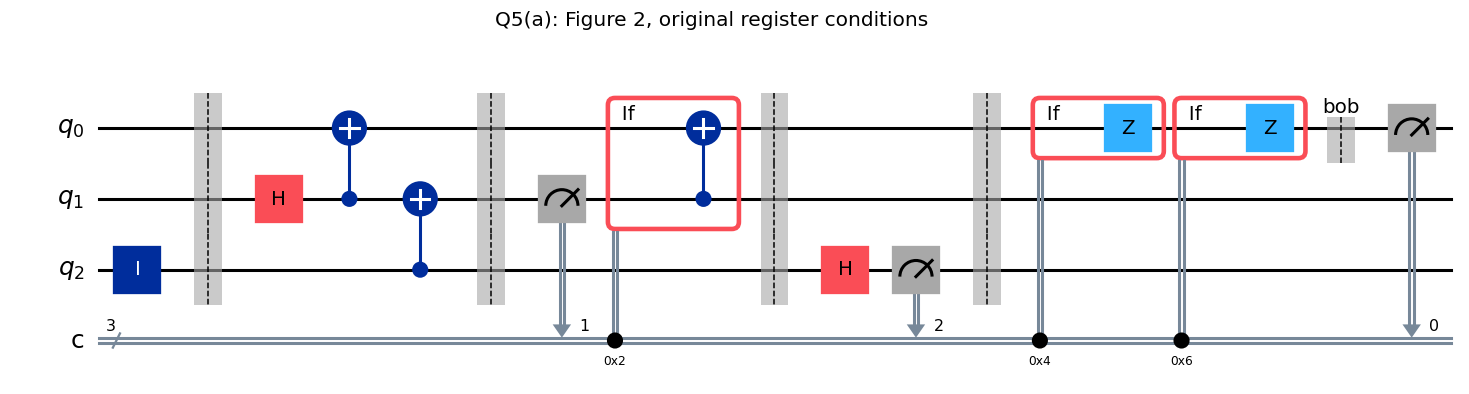

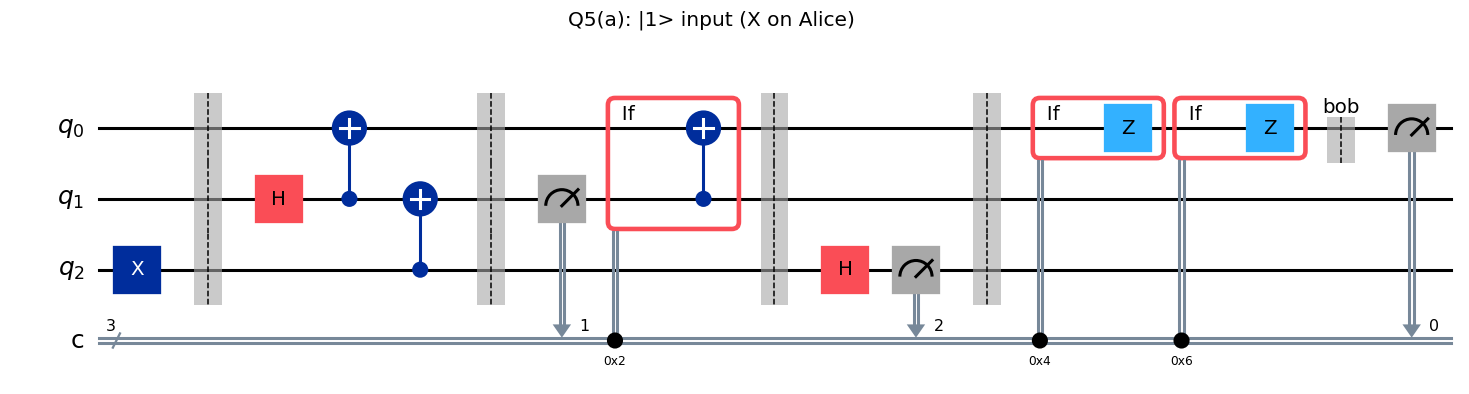

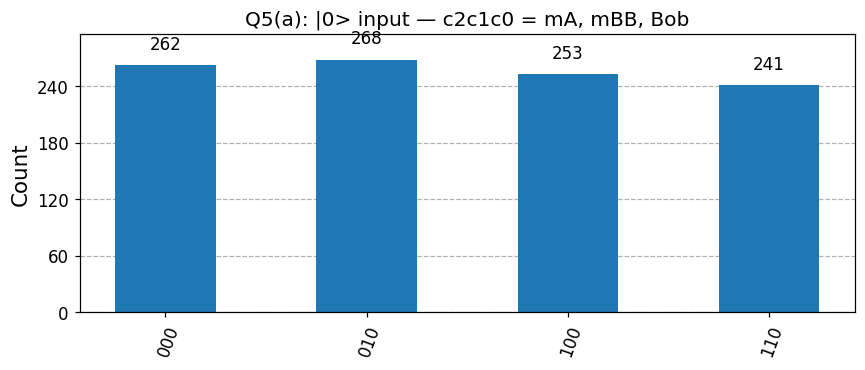

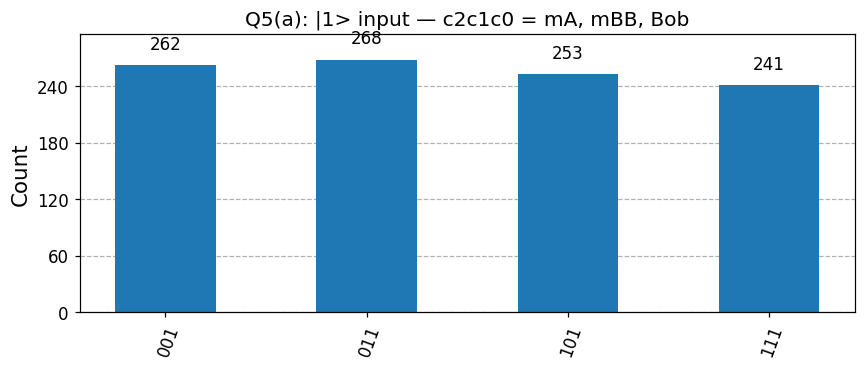

In [9]:
def full_teleport(psi, layout="original", conditions="register",
                  readout=True, correction=True):
    # Literal staged Figure 2; snapshot precedes Bob's final measurement.
    psi = np.asarray(psi,dtype=complex)
    if psi.shape != (2,) or not np.isclose(np.vdot(psi,psi).real,1):
        raise ValueError("psi must be a normalized two-component statevector")
    if layout not in {"original","remapped"}:
        raise ValueError("Unknown layout")
    if conditions not in {"register","bit"}:
        raise ValueError("Unknown condition mode")
    cBB,cA,cB = (1,2,0) if layout=="original" else (0,1,2)
    qc = QuantumCircuit(3,3,name=f"teleport_{layout}")
    if np.allclose(psi,[1,0]):
        qc.id(2)
    elif np.allclose(psi,[0,1]):
        qc.x(2)
    else:
        qc.initialize(psi,[2])
    qc.barrier()
    qc.h(1)
    qc.cx(1,0)
    qc.cx(2,1)
    qc.barrier()
    qc.measure(1,cBB)
    if correction:
        condition = (qc.cregs[0],1<<cBB) if conditions=="register" else (qc.clbits[cBB],1)
        with qc.if_test(condition):
            qc.cx(1,0)        # Literal measured-control CX from the supplied figure.
    qc.barrier()
    qc.h(2)
    qc.measure(2,cA)
    qc.barrier()
    if correction:
        if conditions=="register":
            for value in [1<<cA,(1<<cA)+(1<<cBB)]:
                with qc.if_test((qc.cregs[0],value)):
                    qc.z(0)
        else:
            with qc.if_test((qc.clbits[cA],1)):
                qc.z(0)
    qc.save_density_matrix([0],label="bob")
    if readout:
        qc.measure(0,cB)
    return qc

zero_np, one_np = np.array([1,0],complex),np.array([0,1],complex)
q5_0 = full_teleport(zero_np)
q5_1 = full_teleport(one_np)
draw(q5_0, "Q5(a): Figure 2, original register conditions", fold=24)
draw(q5_1, "Q5(a): |1> input (X on Alice)", fold=24)
r5_0,r5_1 = run_aer(q5_0),run_aer(q5_1)
histogram(r5_0.get_counts(), "Q5(a): |0> input — c2c1c0 = mA, mBB, Bob")
histogram(r5_1.get_counts(), "Q5(a): |1> input — c2c1c0 = mA, mBB, Bob")
check("|0> output support matches Figure 3",set(r5_0.get_counts())=={"000","010","100","110"})
check("|1> output support matches Figure 3",set(r5_1.get_counts())=={"001","011","101","111"})
for label,result,psi in [("0",r5_0,zero_np),("1",r5_1,one_np)]:
    fidelity = state_fidelity(DensityMatrix(result.data()["bob"]),Statevector(psi))
    check(f"|{label}> input: Bob fidelity is 1",abs(fidelity-1)<TOL)

### 5(b). Remap the classical bits and update the conditions

**Interpretation of wording.** The PDF asks to store the “Step 3 measurement”
in classical bit 1. The measurement determining the Z correction is Alice's
$q_2$ measurement, drawn under **Step 2**. We map it to c[1], consistent with
the hint. Bob's final measurement occurs after the correction and cannot
supply its control information.

| Meaning | Original | Remapped |
|---|---|---|
| $m_{BB}$, measured $q_1$ | c[1] | c[0] |
| $m_A$, measured $q_2$ | c[2] | c[1] |
| Bob's final result, measured $q_0$ | c[0] | c[2] |

The whole-register value is now $c_0+2c_1+4c_2$.
At the X correction stage only c[0] has been written. At the Z correction
stage Bob has not yet been measured, so c[2]=0.

| Gate/stage | Old integer condition | New integer condition | Direct bit condition |
|---|---|---|---|
| Step 1b conditional CX | register == 2 | **register == 1** | c[0] == 1 |
| Step 3 Z | register == 4 or 6 | **register == 2 or 3** | c[1] == 1 |

Only one whole-register Z case is true in any run; these are alternatives,
not two Z operations on the same branch. Bit conditions are easier to maintain
because they do not depend on the other register bits.

With the new layout, Bob is the leftmost output bit. For $|0\rangle$, expect
000,001,010,011; for $|1\rangle$, expect 100,101,110,111, each with probability
$1/4$. These are the same physical outcomes encoded differently.
To compare to Figure 3, relabel b mA mBB back to mA mBB b.

PASS: Remapped |0> support is correct
|0> remapped counts: {'001': 268, '010': 253, '000': 262, '011': 241}
Relabeled to the original bit order: {'010': 268, '100': 253, '000': 262, '110': 241}
PASS: Remapped |1> support is correct
|1> remapped counts: {'110': 253, '101': 268, '100': 262, '111': 241}
Relabeled to the original bit order: {'101': 253, '011': 268, '001': 262, '111': 241}


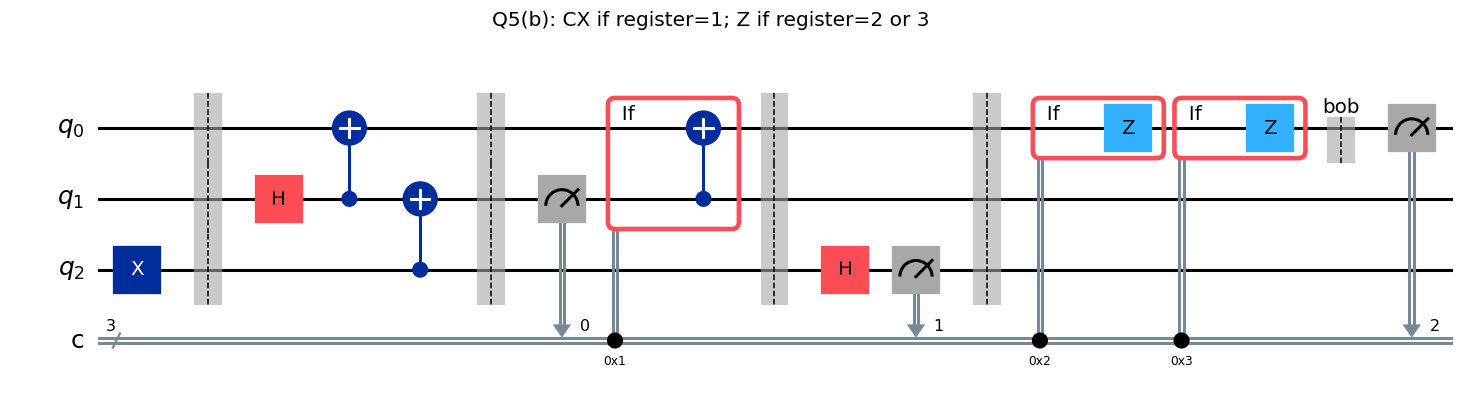

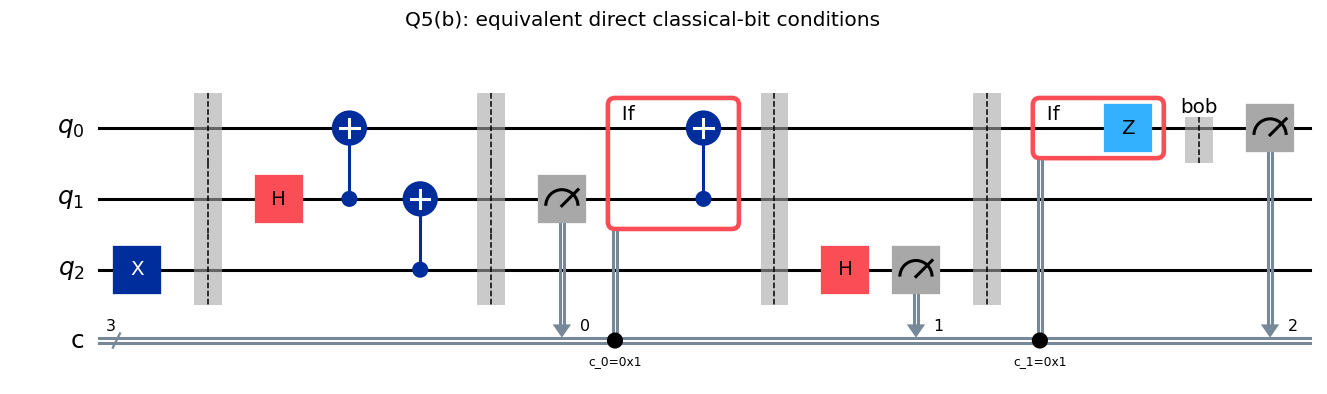

In [10]:
q5_remap = full_teleport(one_np,"remapped","register")
draw(q5_remap, "Q5(b): CX if register=1; Z if register=2 or 3", fold=24)
q5_bits = full_teleport(one_np,"remapped","bit")
draw(q5_bits, "Q5(b): equivalent direct classical-bit conditions", fold=24)
remap_results = {}
for label,psi,expected in [
    ("0",zero_np,{"000","001","010","011"}),
    ("1",one_np,{"100","101","110","111"})]:
    result = run_aer(full_teleport(psi,"remapped","register"))
    remap_results[label]=result
    check(f"Remapped |{label}> support is correct",set(result.get_counts())==expected)
    restored = {}
    for bits,n in result.get_counts().items():
        original_order = bits[1:] + bits[0]
        restored[original_order]=n
    print(f"|{label}> remapped counts:",result.get_counts())
    print("Relabeled to the original bit order:",restored)

### Verify phases and arbitrary states, not only basis-state counts

Z-basis tests of $|0\rangle$ and $|1\rangle$ cannot detect a missing
phase correction. We also test $|+\rangle,|-\rangle,|+i\rangle$, a
complex-amplitude input, and reproducible random states, using both register
layouts and both forms of classical condition.

First the matrix identity below checks **all four exact measurement branches**
for symbolic $\alpha,\beta$, before finite-shot sampling. Aer then checks
Bob's saved density matrix before final measurement. The fidelity convention is
$F(\rho_B,|\psi\rangle)=\langle\psi|\rho_B|\psi\rangle$, equal to 1 for
perfect transfer.

In [11]:
# Exact branches in the standard deferred-correction form.
after_H4 = sp.simplify(sp.kronecker_product(H,sp.eye(4))*v_out4)
for mA,mBB in product([0,1],repeat=2):
    branch = after_H4[4*mA+2*mBB:4*mA+2*mBB+2,0]
    corrected = sp.simplify((Z**mA)*(X**mBB)*branch)
    check(f"Exact branch mA={mA}, mBB={mBB}: corrected amplitude = psi/2",
          corrected == sp.Matrix([alpha,beta])/2)
print("Each branch has norm^2=(|alpha|^2+|beta|^2)/4=1/4.")

test_states = {
    "0":zero_np, "1":one_np, "+":as_np(plus).ravel(),
    "-":as_np(minus).ravel(), "+i":np.array([1,1j])/np.sqrt(2),
    "complex":v_complex}
for i in range(4):
    v = rng.normal(size=2)+1j*rng.normal(size=2)
    test_states[f"random_{i}"]=v/np.linalg.norm(v)
verification_rows=[]
for name,psi in test_states.items():
    fidelities=[]
    for layout,mode in product(["original","remapped"],["register","bit"]):
        result=run_aer(full_teleport(psi,layout,mode))
        rho=DensityMatrix(result.data()["bob"])
        f=float(state_fidelity(rho,Statevector(psi)))
        assert abs(f-1)<TOL,(name,layout,mode,f)
        fidelities.append(f)
    verification_rows.append([name, f"{min(fidelities):.12f}", "4 / 4 passed"])
table(["Input state","Minimum fidelity across layouts/conditions","Configurations"],verification_rows)
print(f"PASS: {len(test_states)*4} Aer state-transfer checks, tolerance {TOL}.")

uncorrected = run_aer(full_teleport(as_np(plus).ravel(),correction=False))
f_uncorrected = state_fidelity(DensityMatrix(uncorrected.data()["bob"]),Statevector(as_np(plus).ravel()))
print(f"Without either correction, |+> input gives average fidelity {f_uncorrected:.6f}.")
# Measurement branches are sampled. The saved matrix is averaged over those
# sampled branches, so its uncorrected fidelity fluctuates around 1/2.
six_sigma = 6*np.sqrt(0.25/SHOTS)
check("Negative control: fidelity near 1/2 within finite-shot tolerance",
      abs(f_uncorrected-.5)<six_sigma)
check("Negative control: fidelity substantially below a successful transfer",
      f_uncorrected<0.9)
rho_uncorrected_exact = sp.eye(2)/2
show_matrix(r"\rho_{B,\mathrm{uncorrected}}^{\mathrm{exact}}",rho_uncorrected_exact)

PASS: Exact branch mA=0, mBB=0: corrected amplitude = psi/2
PASS: Exact branch mA=0, mBB=1: corrected amplitude = psi/2
PASS: Exact branch mA=1, mBB=0: corrected amplitude = psi/2
PASS: Exact branch mA=1, mBB=1: corrected amplitude = psi/2
Each branch has norm^2=(|alpha|^2+|beta|^2)/4=1/4.
PASS: 40 Aer state-transfer checks, tolerance 1e-10.
Without either correction, |+> input gives average fidelity 0.517578.
PASS: Negative control: fidelity near 1/2 within finite-shot tolerance
PASS: Negative control: fidelity substantially below a successful transfer


| Input state | Minimum fidelity across layouts/conditions | Configurations |
| --- | --- | --- |
| 0 | 1.000000000000 | 4 / 4 passed |
| 1 | 1.000000000000 | 4 / 4 passed |
| + | 1.000000000000 | 4 / 4 passed |
| - | 1.000000000000 | 4 / 4 passed |
| +i | 1.000000000000 | 4 / 4 passed |
| complex | 1.000000000000 | 4 / 4 passed |
| random_0 | 1.000000000000 | 4 / 4 passed |
| random_1 | 1.000000000000 | 4 / 4 passed |
| random_2 | 1.000000000000 | 4 / 4 passed |
| random_3 | 1.000000000000 | 4 / 4 passed |

<IPython.core.display.Math object>

## 6. Quantum teleportation versus hypothetical teleportation

### 6(1). Why is the original electron's state destroyed?

The electron itself is not annihilated by the teleportation algorithm.
Its **original unknown quantum state** no longer remains on Alice's system.
Alice entangles the input with her Bell-pair qubit and measures both in the
Bell-measurement procedure. In the circuit's measurement frame her qubits
end in the recorded computational-basis states; the two bits do not contain
a full classical description of $\alpha,\beta$.

After Bob's correction the branch structure is
$$
\rho_{\mathrm{Alice\ record},B}
=\frac14\sum_{m_A,m_{BB}}
|m_A m_{BB}\rangle\langle m_A m_{BB}|
\otimes|\psi\rangle\langle\psi|_B.
$$
Alice's original qubit is not an additional $|\psi\rangle$ copy. A universal
teleporter that preserved her unknown input while producing another perfect
copy at Bob would be a universal cloner. Measurement consumes the unknown
input encoding, and the protocol consumes the shared entanglement resource.

### 6(2). What would be required to teleport oneself to the Moon/Mars and back?

In an idealized model, first specify a finite quantum register of $n$ qubits
representing the state to transfer. One must:

1. Distribute and preserve **$n$ high-fidelity Bell pairs** between departure
   and arrival sites, with receiving physical systems and quantum memories
   at the destination.
2. Perform $n$ Bell measurements on the original register and local Bell
   halves. This consumes the original encoding; an arbitrary unknown state
   cannot be retained as a backup copy.
3. Send the **$2n$ classical measurement bits** through ordinary communication
   and apply the corresponding Pauli corrections at the destination.
   The receiver cannot complete the protocol before this information arrives.
4. For the return journey establish a **fresh set of $n$ Bell pairs**,
   receiving systems on Earth, and a return classical communication link.
   The idealized round trip consumes $2n$ Bell pairs and communicates $4n$
   classical bits in total.

This is a quantum-information protocol, not a demonstrated method of
transporting a person. A human is not an isolated controllable $n$-qubit
register: complete encoding, isolation, coherent operations, error correction,
and reconstruction are far beyond present capability. Teleportation transfers
the encoded state to pre-existing receiving systems, not the original matter.
Classical communication prevents faster-than-light travel or signaling.
The resource counts above are logical idealized counts, before physical
error-correction overhead.

### 6(3). If Alice's state is known to be $|0\rangle$, do we need teleportation?

No. If both know it is $|0\rangle$, Bob can locally initialize/reset to
$|0\rangle$. If the input is promised to belong to the orthogonal set
$\{|0\rangle,|1\rangle\}$, Alice may measure Z, send one classical bit,
and let Bob prepare that state. Keeping Alice's known state does not violate
no-cloning: the theorem prohibits one fixed device copying arbitrary
unknown nonorthogonal states.

If the actual input happens to be $|0\rangle$ but Bob has no such promise,
blindly preparing $|0\rangle$ is not a general unknown-state transfer protocol.
A local pure $|0\rangle$ is unentangled with any reference. A genuinely
unknown qubit entangled with a reference requires preserving the joint
quantum information, not just local Z-basis statistics.

## 7. Other forms of $f(x)$

The oracle is a reversible two-qubit map
$$
U_f|x\rangle|y\rangle=|x\rangle|y\oplus f(x)\rangle,
$$
not an irreversible replacement of $y$ by $f(x)$.
The input bit $x$ is preserved. Matrices use
$(|00\rangle,|01\rangle,|10\rangle,|11\rangle)$, with $x=q_1,y=q_0$.

### $f_B(0)=0,\ f_B(1)=1$: identity function $f_B(x)=x$
$$
\begin{aligned}
U_B|00\rangle&=|0\rangle|0\oplus0\rangle=|00\rangle,\\
U_B|01\rangle&=|0\rangle|1\oplus0\rangle=|01\rangle,\\
U_B|10\rangle&=|1\rangle|0\oplus1\rangle=|11\rangle,\\
U_B|11\rangle&=|1\rangle|1\oplus1\rangle=|10\rangle.
\end{aligned}
$$
$$
U_B=\begin{pmatrix}1&0&0&0\\0&1&0&0\\0&0&0&1\\0&0&1&0\end{pmatrix}
=\mathrm{CX}_{x\to y}.
$$

### $f_C(0)=1,\ f_C(1)=0$: negation $f_C(x)=1\oplus x$
$$
\begin{aligned}
U_C|00\rangle&=|0\rangle|0\oplus1\rangle=|01\rangle,\\
U_C|01\rangle&=|0\rangle|1\oplus1\rangle=|00\rangle,\\
U_C|10\rangle&=|1\rangle|0\oplus0\rangle=|10\rangle,\\
U_C|11\rangle&=|1\rangle|1\oplus0\rangle=|11\rangle.
\end{aligned}
$$
$$
U_C=\begin{pmatrix}0&1&0&0\\1&0&0&0\\0&0&1&0\\0&0&0&1\end{pmatrix}
=(I\otimes X)\,\mathrm{CX}_{x\to y}.
$$
Implement CX followed by X on $y$, or a CNOT controlled on $x=0$.

### $f_D(0)=1,\ f_D(1)=1$: constant one
$$
\begin{aligned}
U_D|00\rangle&=|0\rangle|0\oplus1\rangle=|01\rangle,\\
U_D|01\rangle&=|0\rangle|1\oplus1\rangle=|00\rangle,\\
U_D|10\rangle&=|1\rangle|0\oplus1\rangle=|11\rangle,\\
U_D|11\rangle&=|1\rangle|1\oplus1\rangle=|10\rangle.
\end{aligned}
$$
$$
U_D=\begin{pmatrix}0&1&0&0\\1&0&0&0\\0&0&0&1\\0&0&1&0\end{pmatrix}
=I\otimes X.
$$
The handout's $f_A$ gives $U_A=I_4$.
Each column is the output for its corresponding input basis vector.

PASS: Oracle A: unitary, self inverse, Qiskit agrees
PASS: Oracle B: unitary, self inverse, Qiskit agrees
PASS: Oracle C: unitary, self inverse, Qiskit agrees
PASS: Oracle D: unitary, self inverse, Qiskit agrees


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

| Oracle | Input xy | f(x) | Output x(y XOR f(x)) |
| --- | --- | --- | --- |
| A | 00 | 0 | 00 |
| A | 01 | 0 | 01 |
| A | 10 | 0 | 10 |
| A | 11 | 0 | 11 |
| B | 00 | 0 | 00 |
| B | 01 | 0 | 01 |
| B | 10 | 1 | 11 |
| B | 11 | 1 | 10 |
| C | 00 | 1 | 01 |
| C | 01 | 1 | 00 |
| C | 10 | 0 | 10 |
| C | 11 | 0 | 11 |
| D | 00 | 1 | 01 |
| D | 01 | 1 | 00 |
| D | 10 | 1 | 11 |
| D | 11 | 1 | 10 |

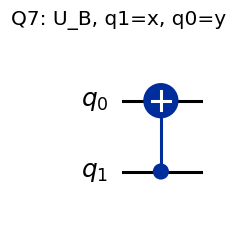

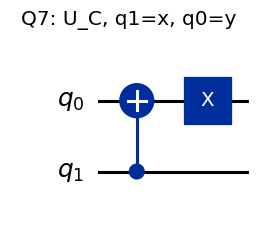

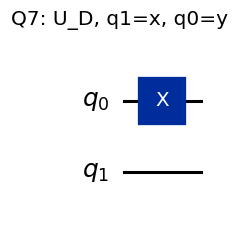

In [12]:
functions = {"A":(0,0),"B":(0,1),"C":(1,0),"D":(1,1)}

def oracle_matrix(f):
    matrix=np.zeros((4,4),dtype=complex)
    for x,y in product([0,1],repeat=2):
        matrix[2*x+(y^f[x]),2*x+y]=1
    return matrix

def append_oracle(qc,name,x=1,y=0):
    if name=="A":
        qc.id(y)
    elif name=="B":
        qc.cx(x,y)
    elif name=="C":
        qc.cx(x,y)
        qc.x(y)
    elif name=="D":
        qc.x(y)
    else:
        raise ValueError(name)

oracle_matrices={}
truth_rows=[]
for name,f in functions.items():
    U=oracle_matrix(f)
    oracle_matrices[name]=U
    qc=QuantumCircuit(2,name=f"Uf_{name}")
    append_oracle(qc,name)
    show_matrix(r"U_"+name,sp.Matrix(U).applyfunc(sp.nsimplify))
    check(f"Oracle {name}: unitary, self inverse, Qiskit agrees",
          np.allclose(U.conj().T@U,np.eye(4),atol=TOL) and
          np.allclose(U@U,np.eye(4),atol=TOL) and
          np.allclose(Operator(qc).data,U,atol=TOL))
    for x,y in product([0,1],repeat=2):
        observed=np.argmax(np.abs(U[:,2*x+y]))
        expected=2*x+(y^f[x])
        assert observed==expected
        truth_rows.append([name,f"{x}{y}",f[x],f"{x}{y^f[x]}"])
table(["Oracle","Input xy","f(x)","Output x(y XOR f(x))"],truth_rows)
for name in ["B","C","D"]:
    qc=QuantumCircuit(2,name=f"Uf_{name}")
    append_oracle(qc,name)
    draw(qc,f"Q7: U_{name}, q1=x, q0=y")

## 8. Creation of superposition using matrices

Interpret the handout's $(HH)(IX)$ as
$(H\otimes H)(I\otimes X)$, not ordinary multiplication $HHIX$
on one qubit.
$$
|00\rangle=\begin{pmatrix}1\\0\\0\\0\end{pmatrix},\quad
I\otimes X=\begin{pmatrix}
0&1&0&0\\1&0&0&0\\0&0&0&1\\0&0&1&0
\end{pmatrix}.
$$
First,
$$
(I\otimes X)|00\rangle
=\begin{pmatrix}0\\1\\0\\0\end{pmatrix}=|01\rangle.
$$
Then
$$
H\otimes H=\frac12\begin{pmatrix}
1&1&1&1\\1&-1&1&-1\\1&1&-1&-1\\1&-1&-1&1
\end{pmatrix},
$$
so
$$
(H\otimes H)|01\rangle
=\frac12\begin{pmatrix}1\\-1\\1\\-1\end{pmatrix}
=\frac{|00\rangle-|01\rangle+|10\rangle-|11\rangle}{2}
=|+\rangle|-\rangle.
$$
The mixed-product rule also gives
$(H\otimes H)(I\otimes X)=(HI)\otimes(HX)=H\otimes HX$,
which sends $|0\rangle|0\rangle$ to $H|0\rangle\otimes H|1\rangle$.

PASS: Matrix result equals |+> tensor |->
PASS: Qiskit statevector matches the matrix result


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

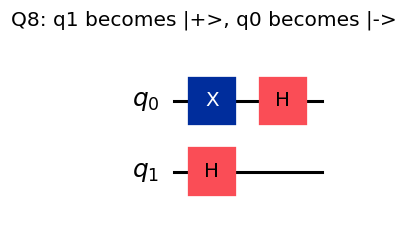

In [13]:
IX = sp.kronecker_product(I,X)
HH = sp.kronecker_product(H,H)
v00=sp.Matrix([1,0,0,0])
v01=sp.simplify(IX*v00)
v8=sp.simplify(HH*v01)
show_matrix(r"I\otimes X",IX)
show_matrix(r"H\otimes H",HH)
show_matrix(r"(H\otimes H)(I\otimes X)|00\rangle",v8)
check("Matrix result equals |+> tensor |->",v8==sp.kronecker_product(plus,minus))
q8=QuantumCircuit(2)
q8.x(0)
q8.h([0,1])
draw(q8,"Q8: q1 becomes |+>, q0 becomes |->")
check("Qiskit statevector matches the matrix result",
      np.allclose(Statevector.from_instruction(q8).data,as_np(v8).ravel(),atol=TOL,rtol=0))

## 9. Hadamard transform of a two-qubit basis state

Use
$$
H^{\otimes n}|y\rangle
=\frac1{2^{n/2}}\sum_{x=0}^{2^n-1}(-1)^{x\cdot y}|x\rangle,\quad
x\cdot y=\left(\sum_j x_j y_j\right)\bmod2.
$$
Here $n=2$ and the **input bit string** is $y=01$. (This $y$ labels
the entire two-bit input in the formula, not only the work qubit.)
Let $x=x_1x_0$. Then
$$
x\cdot01=(x_1\cdot0+x_0\cdot1)\bmod2=x_0.
$$

| $x$ | $x_1\cdot0+x_0\cdot1\bmod2$ | $(-1)^{x\cdot01}$ | Term |
|---|---|---|---|
| 00 | 0 | $+1$ | $+\vert 00\rangle/2$ |
| 01 | 1 | $-1$ | $-\vert 01\rangle/2$ |
| 10 | 0 | $+1$ | $+\vert 10\rangle/2$ |
| 11 | 1 | $-1$ | $-\vert 11\rangle/2$ |

Consequently,
$$
H^{\otimes2}|01\rangle
=\frac12(|00\rangle-|01\rangle+|10\rangle-|11\rangle)
=|+\rangle|-\rangle.
$$
The dot product is a binary inner product, **not** ordinary integer
multiplication of the decimal labels $x$ and $y$.

PASS: Binary-inner-product expansion equals Q8
PASS: Walsh formula gives H tensor H for every basis input


| x | x dot 01 mod 2 | Sign | Amplitude |
| --- | --- | --- | --- |
| 00 | 0 | +1 | +0.5 |
| 01 | 1 | -1 | -0.5 |
| 10 | 0 | +1 | +0.5 |
| 11 | 1 | -1 | -0.5 |

<IPython.core.display.Math object>

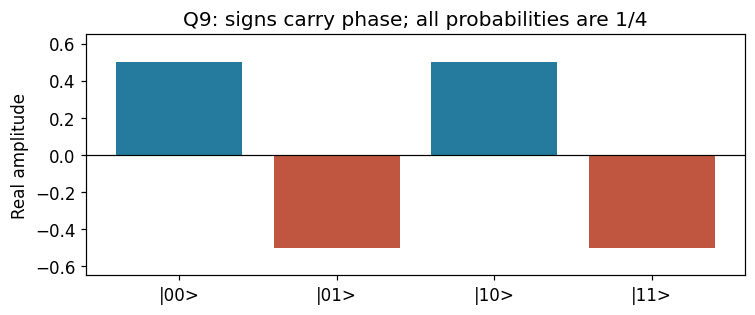

In [14]:
ybits=(0,1)
sign_rows=[]
amplitudes=[]
for x in range(4):
    xbits=((x>>1)&1,x&1)
    parity=sum(a*b for a,b in zip(xbits,ybits))%2
    sign=(-1)**parity
    amplitudes.append(sign/2)
    sign_rows.append([f"{x:02b}",parity,f"{sign:+d}",f"{sign/2:+.1f}"])
table(["x","x dot 01 mod 2","Sign","Amplitude"],sign_rows)
check("Binary-inner-product expansion equals Q8",
      np.allclose(amplitudes,as_np(v8).ravel(),atol=TOL,rtol=0))

walsh=sp.Matrix(4,4,lambda row,col:
    sp.Rational((-1)**((int(row)&int(col)).bit_count()%2),2))
show_matrix(r"W_2",walsh)
check("Walsh formula gives H tensor H for every basis input",walsh==HH)
fig,ax=plt.subplots(figsize=(7,3))
ax.bar([f"|{i:02b}>" for i in range(4)],amplitudes,
       color=["#247b9e" if a>0 else "#c05640" for a in amplitudes])
ax.axhline(0,color="black",linewidth=.8)
ax.set(ylim=(-.65,.65),ylabel="Real amplitude",title="Q9: signs carry phase; all probabilities are 1/4")
fig.tight_layout()
display(fig)
plt.close(fig)

## 10. Non-constant functions in Deutsch's algorithm

For one input bit, a balanced Boolean function has one 0 and one 1 in its
truth table. There are exactly two: $f_B(x)=x$ and $f_C(x)=1\oplus x$.

### Requested basis-by-basis calculation for both balanced functions

For $f_B$:
$$
\begin{aligned}
U_B|0\rangle|0\rangle&=|0\rangle|0\oplus f_B(0)\rangle=|0\rangle|0\oplus0\rangle=|00\rangle,\\
U_B|0\rangle|1\rangle&=|0\rangle|1\oplus f_B(0)\rangle=|0\rangle|1\oplus0\rangle=|01\rangle,\\
U_B|1\rangle|0\rangle&=|1\rangle|0\oplus f_B(1)\rangle=|1\rangle|0\oplus1\rangle=|11\rangle,\\
U_B|1\rangle|1\rangle&=|1\rangle|1\oplus f_B(1)\rangle=|1\rangle|1\oplus1\rangle=|10\rangle.
\end{aligned}
$$
For $f_C$:
$$
\begin{aligned}
U_C|0\rangle|0\rangle&=|0\rangle|0\oplus f_C(0)\rangle=|0\rangle|0\oplus1\rangle=|01\rangle,\\
U_C|0\rangle|1\rangle&=|0\rangle|1\oplus f_C(0)\rangle=|0\rangle|1\oplus1\rangle=|00\rangle,\\
U_C|1\rangle|0\rangle&=|1\rangle|0\oplus f_C(1)\rangle=|1\rangle|0\oplus0\rangle=|10\rangle,\\
U_C|1\rangle|1\rangle&=|1\rangle|1\oplus f_C(1)\rangle=|1\rangle|1\oplus0\rangle=|11\rangle.
\end{aligned}
$$

### Apply the oracle to the superposition

Q8–Q9 give the input
$$
|\chi\rangle=|+\rangle|-\rangle
=\tfrac12(|00\rangle-|01\rangle+|10\rangle-|11\rangle).
$$
For $f_B$, substituting the four mapped basis states:
$$
U_B|\chi\rangle
=\tfrac12(|00\rangle-|01\rangle+|11\rangle-|10\rangle)
=|-\rangle|-\rangle.
$$
For $f_C$,
$$
U_C|\chi\rangle
=\tfrac12(|01\rangle-|00\rangle+|10\rangle-|11\rangle)
=-|-\rangle|-\rangle.
$$
The second result's minus sign is a global phase and has no effect on
measurement probabilities. The final Hadamard on the **input $x$** gives
$|1\rangle|-\rangle$ for B and $-|1\rangle|-\rangle$ for C.
Thus $x$ is **1 with certainty** for either balanced function.

### Phase kickback and comparison with constant functions

Since $X|-\rangle=-|-\rangle$,
$$
U_f|x\rangle|-\rangle=(-1)^{f(x)}|x\rangle|-\rangle.
$$
Hence
$$
U_f|+\rangle|-\rangle
=\frac{(-1)^{f(0)}|0\rangle+(-1)^{f(1)}|1\rangle}{\sqrt2}
\otimes|-\rangle.
$$
After the final $H$ on $x$,
$$
|\mathrm{out}\rangle=
\frac{[(-1)^{f(0)}+(-1)^{f(1)}]|0\rangle
+[(-1)^{f(0)}-(-1)^{f(1)}]|1\rangle}{2}
\otimes|-\rangle.
$$
Therefore $x=f(0)\oplus f(1)$ is obtained using **one oracle query**.

| Function | $(f(0),f(1))$ | After oracle | After final $H_x$ | Measured $x$ |
|---|---|---|---|---|
| A | (0,0) | $\vert +\rangle\vert -\rangle$ | $\vert 0\rangle\vert -\rangle$ | 0, constant |
| B | (0,1) | $\vert -\rangle\vert -\rangle$ | $\vert 1\rangle\vert -\rangle$ | 1, balanced |
| C | (1,0) | $-\vert -\rangle\vert -\rangle$ | $-\vert 1\rangle\vert -\rangle$ | 1, balanced |
| D | (1,1) | $-\vert +\rangle\vert -\rangle$ | $-\vert 0\rangle\vert -\rangle$ | 0, constant |

This is the exact one-bit Deutsch promise problem: one quantum query versus
two classical deterministic queries for certainty. It does not mean both
function values can be read out from the qubits.

PASS: all four Deutsch functions classified exactly with one oracle query each.


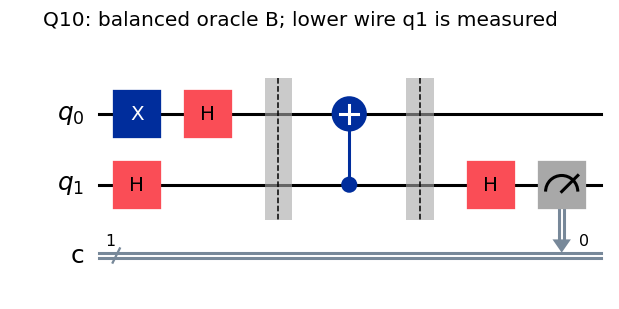

<IPython.core.display.Math object>

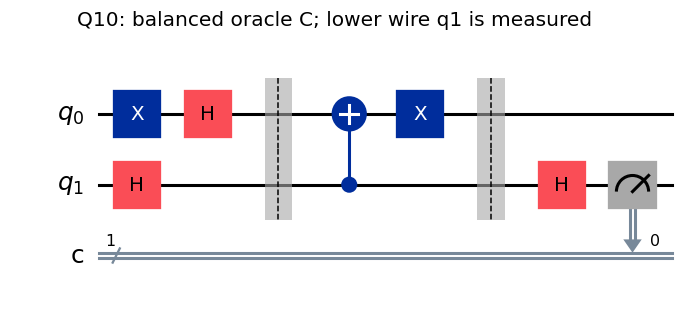

<IPython.core.display.Math object>

| Function | (f(0), f(1)) | Class | Exact P(x=0), P(x=1) | Aer counts |
| --- | --- | --- | --- | --- |
| A | (0, 0) | constant | [1.0, 0.0] | {'0': 1024} |
| B | (0, 1) | balanced | [0.0, 1.0] | {'1': 1024} |
| C | (1, 0) | balanced | [0.0, 1.0] | {'1': 1024} |
| D | (1, 1) | constant | [1.0, 0.0] | {'0': 1024} |

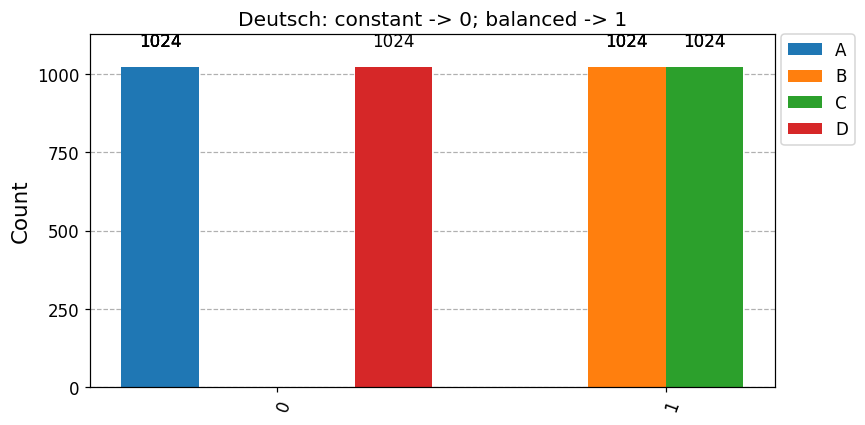

In [15]:
def deutsch_circuit(name,measure=True):
    qc=QuantumCircuit(2,1,name=f"Deutsch_{name}")
    qc.x(0)                 # Work qubit y = 1.
    qc.h([0,1])             # |x y> = |+ ->.
    qc.barrier()
    append_oracle(qc,name)  # One call to U_f.
    qc.barrier()
    qc.h(1)                 # Only the input x gets the final H.
    if measure:
        qc.measure(1,0)
    return qc

deutsch_counts={}
deutsch_rows=[]
for name,f in functions.items():
    before_oracle=as_np(v8).ravel()
    after_oracle=oracle_matrices[name]@before_oracle
    after_final=as_np(sp.kronecker_product(H,I))@after_oracle
    q_exact=deutsch_circuit(name,False)
    sv=Statevector.from_instruction(q_exact)
    assert np.allclose(sv.data,after_final,atol=TOL,rtol=0)
    expected=f[0]^f[1]
    marginal=sv.probabilities(qargs=[1])
    assert np.isclose(marginal[expected],1,atol=TOL,rtol=0)
    q_measured=deutsch_circuit(name)
    result=run_aer(q_measured)
    counts=result.get_counts()
    assert counts=={str(expected):SHOTS}
    deutsch_counts[name]=counts
    deutsch_rows.append([name,str(f),"balanced" if expected else "constant",
                         np.round(marginal,6).tolist(),str(counts)])
    if name in {"B","C"}:
        draw(q_measured,f"Q10: balanced oracle {name}; lower wire q1 is measured")
        show_matrix(r"U_"+name+r"|+\!-\rangle",sp.Matrix(after_oracle).applyfunc(sp.nsimplify))

table(["Function","(f(0), f(1))","Class","Exact P(x=0), P(x=1)","Aer counts"],deutsch_rows)
fig=plot_histogram([deutsch_counts[k] for k in functions],
                   legend=list(functions),title="Deutsch: constant -> 0; balanced -> 1",
                   figsize=(8,4))
display(fig)
plt.close(fig)
print("PASS: all four Deutsch functions classified exactly with one oracle query each.")